 # 05 Using a drive cycle (Multi-Model Comparison)

 PyBaMM provides a number of example drive cycles that define the instantaneous current which can be read in from csv files. We also install required dependencies.

In [23]:
%pip install "pybamm<=23.9" "numpy<2.0,>=1.26.4" "pandas<2.0" liionpack matplotlib scipy

# MAKE SURE YOU ARE ON PYTHON 3.11 NO NEWER


Note: you may need to restart the kernel to use updated packages.


In [24]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pybamm
import liionpack as lp

# Enable inline plotting for Jupyter
%matplotlib inline


In [25]:
# Import drive cycle from file
# Make sure this path matches your Codespaces directory structure
drive_cycle_path = "../../../../../../../workspaces/liionpacktesting/data/ioniq.csv"
drive_cycle = pd.read_csv(drive_cycle_path, comment="#").to_numpy()


 Let's have a look at the drive cycle. The first column is the time stamp and the second is the current.

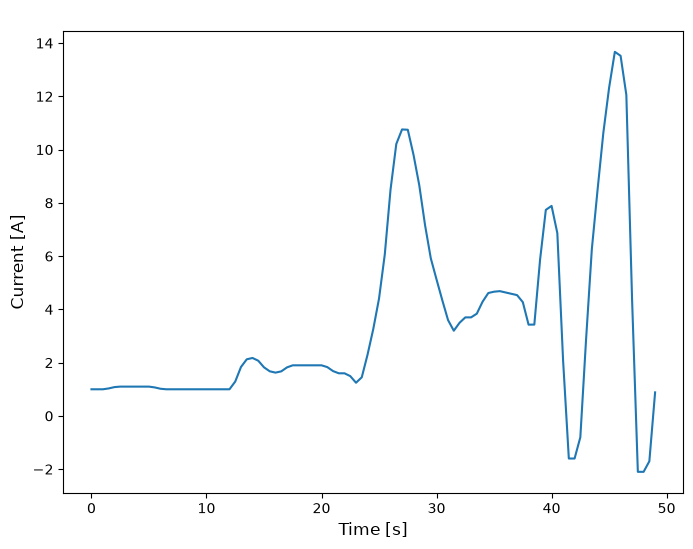

In [38]:
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'none'
    plt.rcParams['axes.facecolor'] = 'none'
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(drive_cycle[:, 0], drive_cycle[:, 1])
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Current [A]")
    ax.set_title("Pack Drive Cycle Current")
    
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)
        
    plt.show()


 Set up our pack circuit, experiment, and parameters.

 We are using a 192s2p architecture.

In [27]:
Np = 2
Ns = 192
netlist = lp.setup_circuit(Np=Np, Ns=Ns, Rb=1e-4, Rc=1e-3, Ri=5e-2, V=4.0, I=14.0)
parameter_values = pybamm.ParameterValues("Chen2020")
initial_soc = 0.965

# Pack-level experiment for liionpack
pack_experiment = pybamm.Experiment(
    [pybamm.step.current(drive_cycle)],
    period="0.5 second",
)


 ## Model 1: SPM in liionpack

 Solves the standard Single Particle Model across all 384 cells.

In [28]:
def spm_sim_func(parameter_values):
    model = pybamm.lithium_ion.SPM()
    model = lp.add_events_to_model(model)
    return pybamm.Simulation(model, parameter_values=parameter_values, experiment=pack_experiment)

print("Solving SPM pack...")
output_spm = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=pack_experiment,
    initial_soc=initial_soc,
    sim_func=spm_sim_func,
)


Solving SPM pack...


Stepping simulation: 100%|██████████| 99/99 [00:17<00:00,  5.69it/s]


 ## Model 2: SPMe in liionpack

 Solves the Single Particle Model with Electrolyte across all 384 cells.

In [29]:
def spme_sim_func(parameter_values):
    model = pybamm.lithium_ion.SPMe()
    model = lp.add_events_to_model(model)
    return pybamm.Simulation(model, parameter_values=parameter_values, experiment=pack_experiment)

print("Solving SPMe pack...")
output_spme = lp.solve(
    netlist=netlist,
    parameter_values=parameter_values,
    experiment=pack_experiment,
    initial_soc=initial_soc,
    sim_func=spme_sim_func,
)


Solving SPMe pack...


Stepping simulation: 100%|██████████| 99/99 [00:28<00:00,  3.43it/s]


 ## Model 3: Lumped DFN in pure PyBaMM

 Since liionpack cannot vectorize DFN across the netlist, we run DFN on a single cell.

 We divide the drive cycle current by Np (2) so the DFN cell experiences the exact same current load as the parallel cells in the liionpack simulation.

In [30]:
print("Solving Lumped DFN...")
# Scale the current for a single cell in a 2P branch
cell_drive_cycle = drive_cycle.copy()
cell_drive_cycle[:, 1] = cell_drive_cycle[:, 1] / Np

dfn_experiment = pybamm.Experiment(
    [pybamm.step.current(cell_drive_cycle)],
    period="0.5 second",
)

dfn_sim = pybamm.Simulation(
    pybamm.lithium_ion.DFN(),
    parameter_values=parameter_values,
    experiment=dfn_experiment
)
dfn_sol = dfn_sim.solve(initial_soc=initial_soc)


Solving Lumped DFN...


 ## Results Comparison and % Differences

 We compare the average cell voltage from the liionpack models to the single cell voltage from the DFN model.

In [31]:
# Extract Data
t_lp = output_spm["Time [s]"]

# Average cell voltages across the 384 cells for liionpack outputs
v_spm = np.mean(output_spm["Terminal voltage [V]"], axis=1)
v_spme = np.mean(output_spme["Terminal voltage [V]"], axis=1)

# PyBaMM DFN times might differ slightly due to internal solver stepping, 
# so we interpolate DFN voltage onto the exact liionpack time vector
t_dfn = dfn_sol["Time [s]"].entries
v_dfn_raw = dfn_sol["Terminal voltage [V]"].entries
v_dfn = np.interp(t_lp, t_dfn, v_dfn_raw)

# Calculate Percentage Differences relative to high-fidelity DFN
diff_spm = np.abs(v_spm - v_dfn) / v_dfn * 100
diff_spme = np.abs(v_spme - v_dfn) / v_dfn * 100

print("--- Maximum Percentage Errors (vs DFN) ---")
print(f"SPM vs DFN:  {np.max(diff_spm):.4f}%")
print(f"SPMe vs DFN: {np.max(diff_spme):.4f}%")
print("------------------------------------------")


--- Maximum Percentage Errors (vs DFN) ---
SPM vs DFN:  2.2623%
SPMe vs DFN: 2.7544%
------------------------------------------


In [35]:
# Assume t_lp, v_spm, v_spme already exist
# and dfn_sol has been built

t_dfn = np.asarray(dfn_sol["Time [s]"].entries)
v_dfn_raw = np.asarray(dfn_sol["Terminal voltage [V]"].entries)

# Sort
order = np.argsort(t_dfn)
t_dfn = t_dfn[order]
v_dfn_raw = v_dfn_raw[order]

# One-step shift to account for time-index offset
dt = np.median(np.diff(t_lp))  # typical pack timestep
t_dfn_shifted = t_dfn + dt

# Interpolate DFN onto pack time grid
v_dfn = np.interp(t_lp, t_dfn_shifted, v_dfn_raw)

diff_spm = np.abs(v_spm - v_dfn) / v_dfn * 100
diff_spme = np.abs(v_spme - v_dfn) / v_dfn * 100

t_dfn_shifted = t_dfn + 0.5 * dt

print("Typical pack dt:", np.median(np.diff(t_lp)))
print("Typical DFN dt:", np.median(np.diff(t_dfn)))

t_dfn_shifted = t_dfn + np.median(np.diff(t_lp))

Typical pack dt: 0.5
Typical DFN dt: 0.5


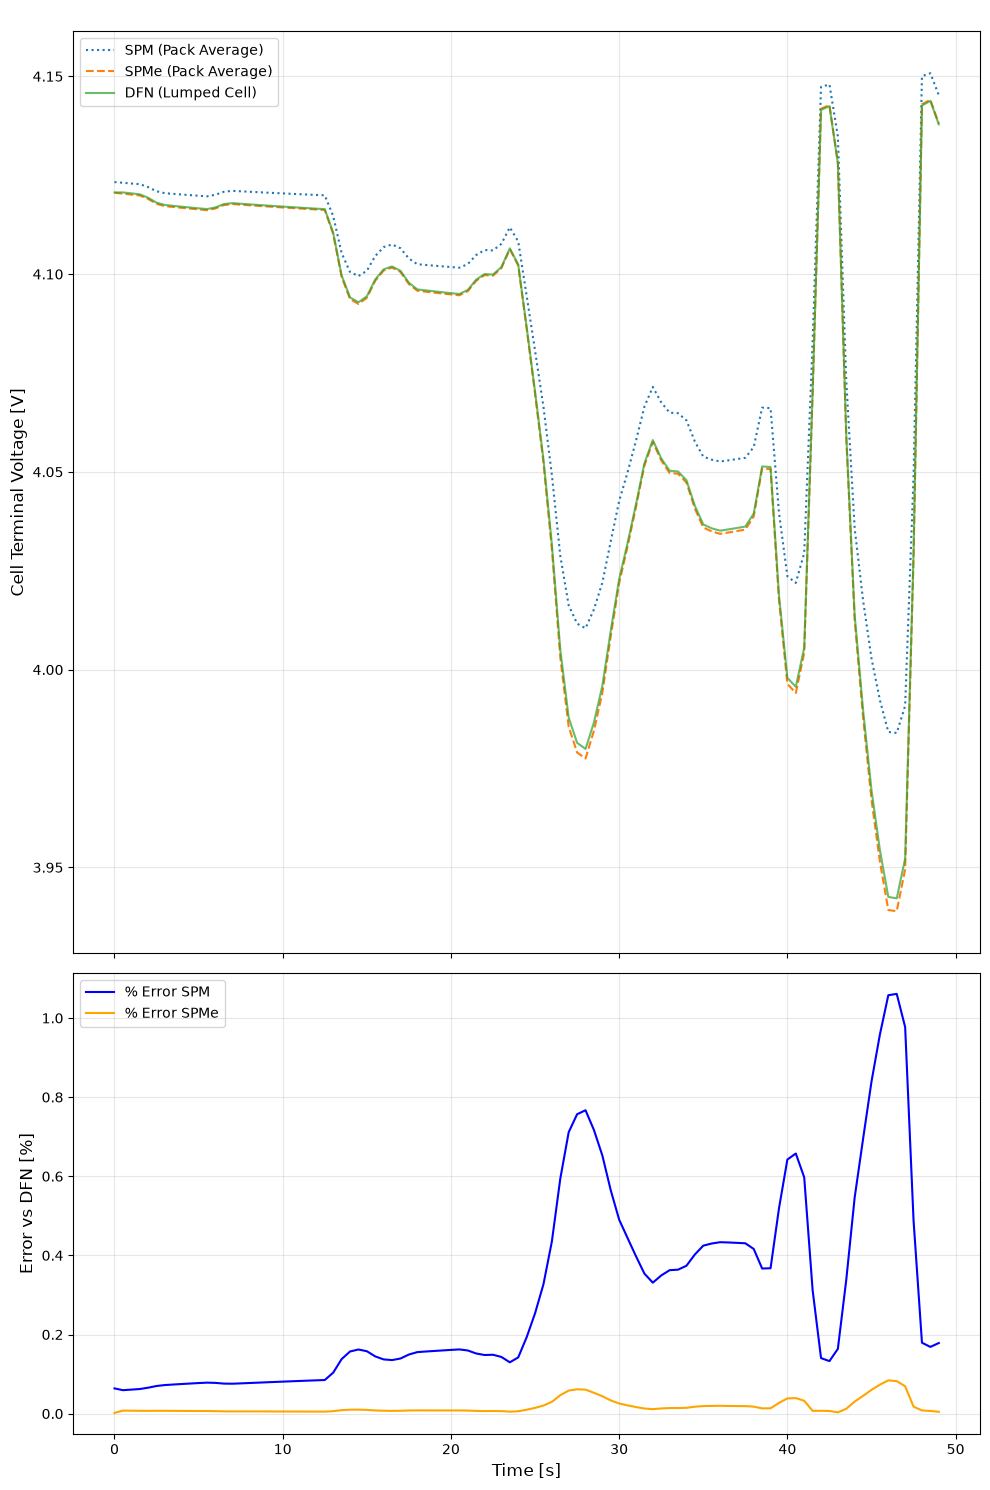

In [39]:
# Plotting the Comparison
with plt.rc_context(lp.lp_context()):
    plt.rcParams['figure.facecolor'] = 'none'
    plt.rcParams['axes.facecolor'] = 'none'
    plt.rcParams['text.color'] = 'black'
    plt.rcParams['axes.labelcolor'] = 'black'
    plt.rcParams['xtick.color'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.edgecolor'] = 'black'
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 15), gridspec_kw={'height_ratios': [2, 1]}, sharex=True)
    
    # Top Plot: Voltage Curves
    ax1.plot(t_lp, v_spm, label="SPM (Pack Average)", linestyle=':')
    ax1.plot(t_lp, v_spme, label="SPMe (Pack Average)", linestyle='--')
    ax1.plot(t_dfn, v_dfn, label="DFN (Lumped Cell)", alpha=0.7)
    ax1.set_ylabel("Cell Terminal Voltage [V]")
    ax1.set_title("Voltage Comparison Under Drive Cycle")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Bottom Plot: Percentage Error
    ax2.plot(t_lp, diff_spm, label="% Error SPM", color="blue")
    ax2.plot(t_lp, diff_spme, label="% Error SPMe", color="orange")
    ax2.set_xlabel("Time [s]")
    ax2.set_ylabel("Error vs DFN [%]")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    for ax in [ax1, ax2]:
        for spine in ax.spines.values():
            spine.set_edgecolor('black')
            spine.set_visible(True)
            
    plt.tight_layout()
    plt.show()


 *Note: The percentage error spikes generally occur during high-current pulses in the drive cycle where electrolyte diffusion (missing in SPM, present in SPMe/DFN) has the largest impact on overpotential.*